# Heart Disease MLOps Assignment

## 1. Install and import dependencies

This cell installs the UCI dataset helper and MLflow.

In [1]:
%pip -q install ucimlrepo mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 951.8 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.1 MB/s eta 0:00:00ta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 586.6 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 55.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 38.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 1.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 4.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 2.2 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 1.7 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os, sys, json, platform, warnings, subprocess, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
)
from sklearn.base import clone

SEED = 42
ROOT = Path("/kaggle/working/heart_disease_mlops")
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
MODEL_DIR = ROOT / "models"
for p in (DATA_DIR, REPORTS_DIR, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("scikit-learn:", importlib.metadata.version("scikit-learn"))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.18.48+-x86_64-with-glibc2.39
scikit-learn: 1.6.1


## 2. Acquire the UCI Heart Disease dataset

The assignment starter uses UCI dataset ID 45 via `ucimlrepo`. This cell records the source and downloads the feature and target tables.

In [3]:
from ucimlrepo import fetch_ucirepo

uci_heart = fetch_ucirepo(id=45)
X_raw = uci_heart.data.features.copy()
y_raw = uci_heart.data.targets.copy()

print("Source: UCI Machine Learning Repository, Heart Disease, dataset ID 45")
print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())
print("Feature columns:", X_raw.columns.tolist())
print("Target columns:", y_raw.columns.tolist())

Source: UCI Machine Learning Repository, Heart Disease, dataset ID 45
Feature shape: (303, 13)
Target shape: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0


Feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target columns: ['num']


## 3. Validate, combine and clean the data

The common UCI target is `num` with values 0–4. This notebook converts it to binary classification: 0 = absence, values 1–4 = presence. It also treats `?` values as missing if present. 

In [4]:
# Normalize column labels for stable use in code while retaining a record of originals.
X = X_raw.copy()
X.columns = [str(c).strip().lower().replace(" ", "_") for c in X.columns]

y_df = y_raw.copy()
target_col = y_df.columns[0]
y_series = y_df[target_col]

# Treat string question marks as missing; convert numeric-like fields where possible.
X = X.replace("?", np.nan)
for col in X.columns:
    converted = pd.to_numeric(X[col], errors="coerce")
    # Use numeric form when values are numeric or missing; otherwise keep as strings.
    if converted.notna().sum() >= X[col].notna().sum() * 0.8:
        X[col] = converted

y_numeric = pd.to_numeric(y_series, errors="coerce")
valid_target = y_numeric.notna()
X = X.loc[valid_target].reset_index(drop=True)
y_numeric = y_numeric.loc[valid_target].reset_index(drop=True)

print("Original target column:", target_col)
print("Observed target values:", sorted(y_numeric.unique().tolist()))
print("Rows with missing target removed:", int((~valid_target).sum()))

# UCI heart disease target: 0 = no disease, 1–4 = disease present.
y = (y_numeric > 0).astype(int).rename("target")
df = X.copy()
df["target"] = y

print("Final dataset shape (features + target):", df.shape)
print("Class counts:")
display(y.value_counts().rename(index={0:"absence (0)", 1:"presence (1)"}).to_frame("count"))
display(df.head())

Original target column: num
Observed target values: [0, 1, 2, 3, 4]
Rows with missing target removed: 0
Final dataset shape (features + target): (303, 14)
Class counts:


,count
target,
absence (0),164
presence (1),139


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 4. Exploratory Data Analysis (EDA)

These cells create real plots and summary tables from the downloaded dataset.

,missing_count,missing_percent
ca,4,1.32
thal,2,0.66
cp,0,0.00
sex,0,0.00
age,0,0.00
chol,0,0.00
trestbps,0,0.00
fbs,0,0.00
restecg,0,0.00
exang,0,0.00


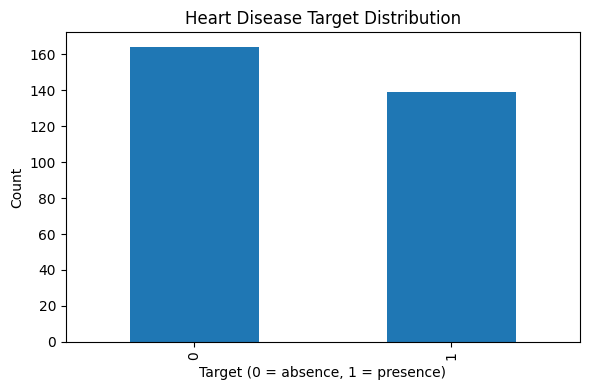

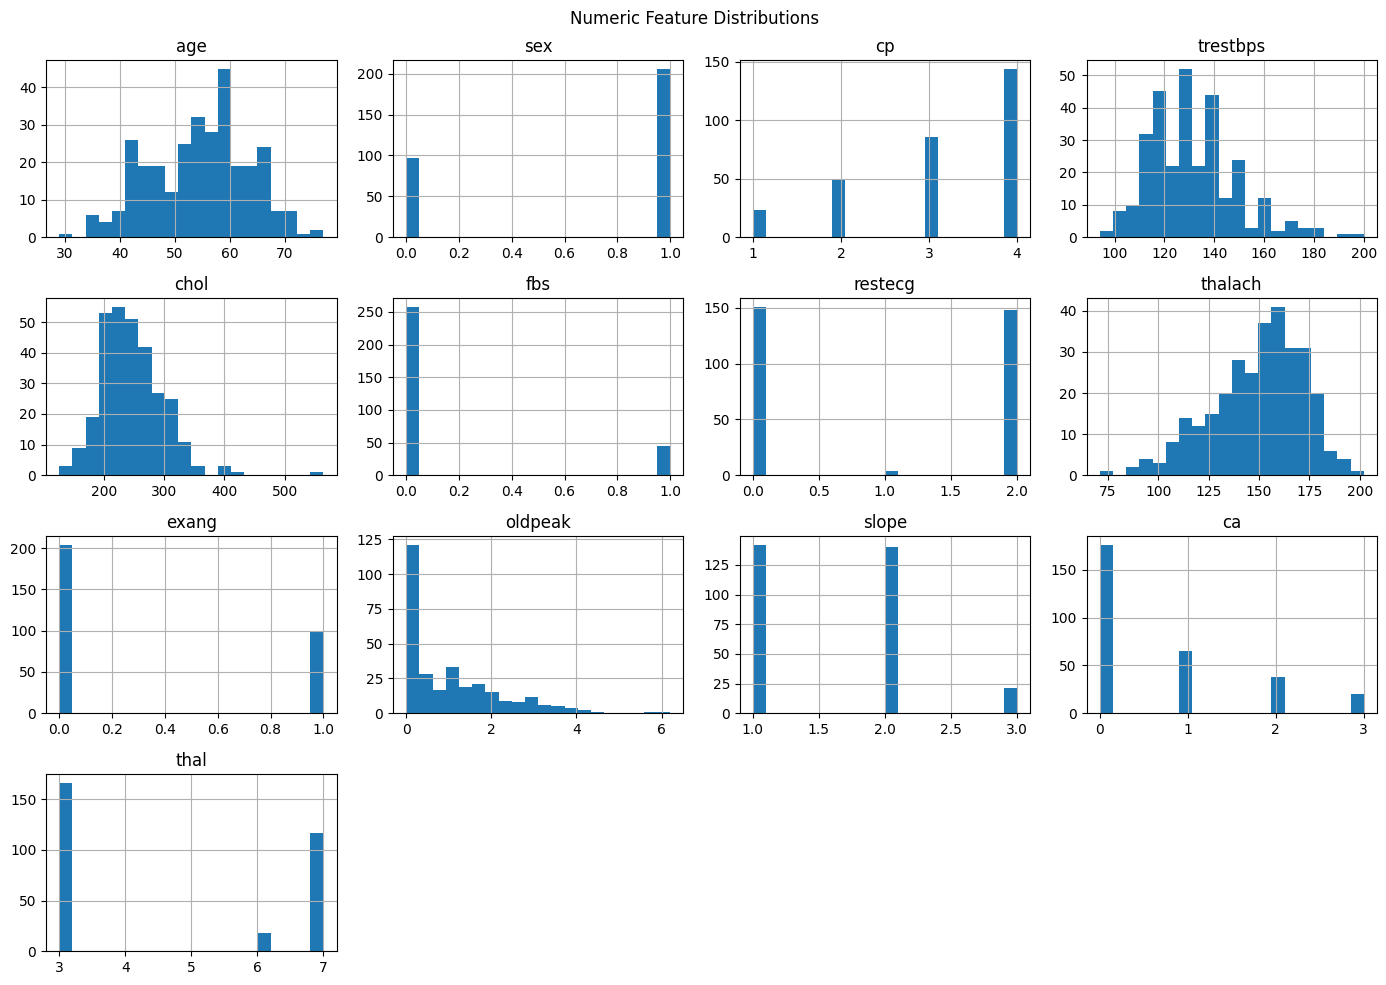

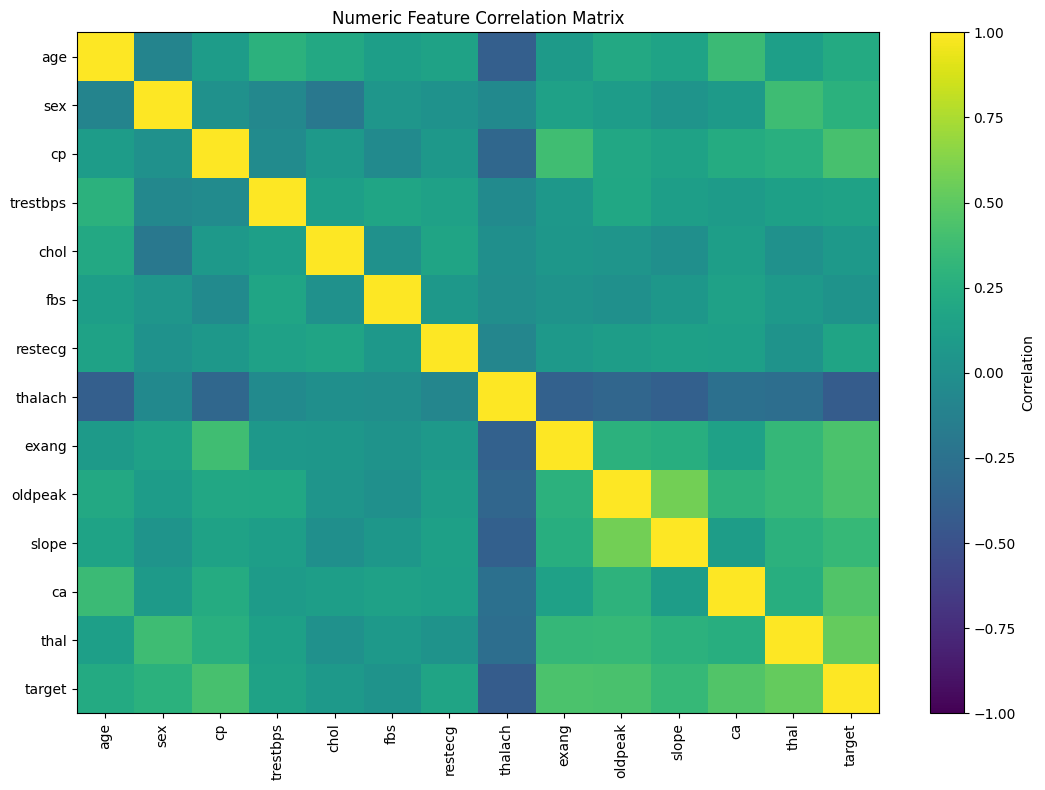

EDA artifacts saved to: /kaggle/working/heart_disease_mlops/reports


In [5]:
# Missingness summary
missing = X.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(X) * 100).round(2)
})
display(missing_summary)
missing_summary.to_csv(REPORTS_DIR / "missing_values.csv")

# Target distribution
fig, ax = plt.subplots(figsize=(6, 4))
y.value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Heart Disease Target Distribution")
ax.set_xlabel("Target (0 = absence, 1 = presence)")
ax.set_ylabel("Count")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "class_balance.png", dpi=160)
plt.show()

# Numeric distributions
numeric_cols_all = X.select_dtypes(include=np.number).columns.tolist()
if numeric_cols_all:
    X[numeric_cols_all].hist(figsize=(14, 10), bins=20)
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / "feature_histograms.png", dpi=160)
    plt.show()

# Correlation heatmap for numeric columns
if len(numeric_cols_all) >= 2:
    corr = df[numeric_cols_all + ["target"]].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(11, 8))
    im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Numeric Feature Correlation Matrix")
    fig.colorbar(im, ax=ax, label="Correlation")
    fig.tight_layout()
    fig.savefig(REPORTS_DIR / "correlation_heatmap.png", dpi=160)
    plt.show()

print("EDA artifacts saved to:", REPORTS_DIR)

## 5. Feature engineering and preprocessing

Some UCI columns are numeric codes for categories, so we explicitly mark known categorical fields as categorical when present. Other columns are treated as numeric. Missing values are imputed inside the pipeline, and scaling/encoding is learned from training data only to reduce leakage.

In [6]:
# Known UCI Heart Disease categorical/code fields; use only fields present in this data.
known_categorical = {"sex", "cp", "fbs", "restecg", "exang", "slope", "thal", "ca"}
categorical_cols = [c for c in X.columns if c.lower() in known_categorical]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

# Convert explicitly categorical fields to strings so OneHotEncoder treats codes as categories.
X_model = X.copy()
for col in categorical_cols:
    X_model[col] = X_model[col].map(lambda v: str(v) if pd.notna(v) else np.nan)

print("Categorical features:", categorical_cols)
print("Numeric features:", numeric_cols)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
transformers = []
if numeric_cols:
    transformers.append(("numeric", numeric_pipeline, numeric_cols))
if categorical_cols:
    transformers.append(("categorical", categorical_pipeline, categorical_cols))
preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Numeric features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


## 6. Train/test split, cross-validation and model selection

We use a stratified 80/20 hold-out split and stratified 5-fold cross-validation on the training portion. The primary model-selection metric is ROC-AUC; accuracy, precision, recall and F1 are also recorded. 

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.20, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

model_specs = {
    "logistic_regression": (
        LogisticRegression(max_iter=2000, random_state=SEED),
        {"model__C": [0.1, 1.0, 10.0]}
    ),
    "random_forest": (
        RandomForestClassifier(random_state=SEED, class_weight="balanced"),
        {"model__n_estimators": [100, 200], "model__max_depth": [None, 5, 10]}
    )
}

fitted_searches = {}
rows = []
for model_name, (estimator, param_grid) in model_specs.items():
    pipeline = Pipeline([("preprocess", clone(preprocessor)), ("model", estimator)])
    scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}
    search = GridSearchCV(
        pipeline, param_grid=param_grid, scoring="roc_auc",
        cv=cv, n_jobs=-1, refit=True, return_train_score=False
    )
    search.fit(X_train, y_train)
    fitted_searches[model_name] = search
    best = search.best_estimator_
    pred = best.predict(X_test)
    prob = best.predict_proba(X_test)[:, 1]
    row = {
        "model": model_name,
        "best_cv_roc_auc": float(search.best_score_),
        "test_accuracy": float(accuracy_score(y_test, pred)),
        "test_precision": float(precision_score(y_test, pred, zero_division=0)),
        "test_recall": float(recall_score(y_test, pred, zero_division=0)),
        "test_f1": float(f1_score(y_test, pred, zero_division=0)),
        "test_roc_auc": float(roc_auc_score(y_test, prob)),
        "best_params": json.dumps(search.best_params_, sort_keys=True)
    }
    rows.append(row)
    print("\nMODEL:", model_name)
    print("Best parameters:", search.best_params_)
    print(classification_report(y_test, pred, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))

results_df = pd.DataFrame(rows).sort_values("best_cv_roc_auc", ascending=False)
display(results_df)
results_df.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
results_df.to_json(REPORTS_DIR / "metrics.json", orient="records", indent=2)


MODEL: logistic_regression
Best parameters: {'model__C': 1.0}
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion matrix:
 [[28  5]
 [ 2 26]]

MODEL: random_forest
Best parameters: {'model__max_depth': 10, 'model__n_estimators': 200}
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion matrix:
 [[28  5]
 [ 2 26]]


,model,best_cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,best_params
0,logistic_regression,0.902493,0.885246,0.83871,0.928571,0.881356,0.966450,"{""model__C"": 1.0}"
1,random_forest,0.899510,0.885246,0.83871,0.928571,0.881356,0.948052,"{""model__max_depth"": 10, ""model__n_estimators""..."


## 7. Evaluation plots and selected model

The selected model is the one with the highest cross-validation ROC-AUC. The test set is used for final reporting, not to tune the hyperparameters.

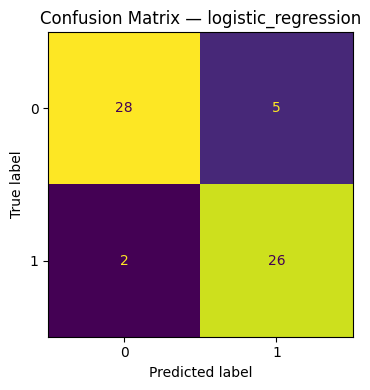

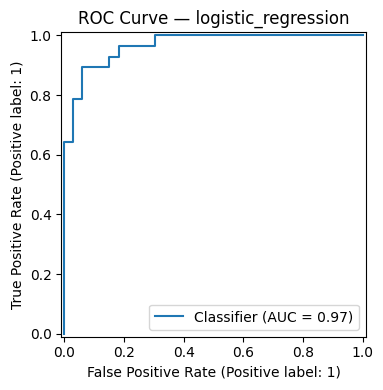

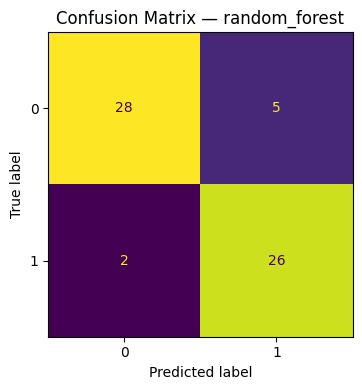

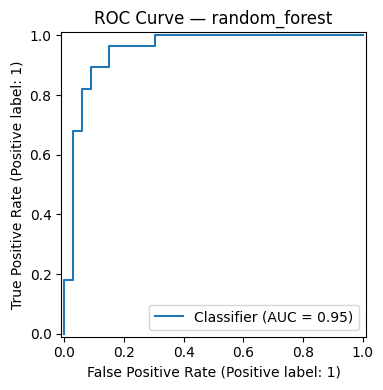

Selected model by CV ROC-AUC: logistic_regression
Best parameters: {'model__C': 1.0}
Hold-out metrics:


,0
model,logistic_regression
best_cv_roc_auc,0.902493
test_accuracy,0.885246
test_precision,0.83871
test_recall,0.928571
test_f1,0.881356
test_roc_auc,0.96645
best_params,"{""model__C"": 1.0}"


In [8]:
for model_name, search in fitted_searches.items():
    best = search.best_estimator_
    pred = best.predict(X_test)
    prob = best.predict_proba(X_test)[:, 1]

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(f"Confusion Matrix — {model_name}")
    fig.tight_layout()
    fig.savefig(REPORTS_DIR / f"confusion_matrix_{model_name}.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 4))
    RocCurveDisplay.from_predictions(y_test, prob, ax=ax)
    ax.set_title(f"ROC Curve — {model_name}")
    fig.tight_layout()
    fig.savefig(REPORTS_DIR / f"roc_curve_{model_name}.png", dpi=160)
    plt.show()

selected_name = results_df.iloc[0]["model"]
selected_search = fitted_searches[selected_name]
selected_model = selected_search.best_estimator_

print("Selected model by CV ROC-AUC:", selected_name)
print("Best parameters:", selected_search.best_params_)
print("Hold-out metrics:")
display(results_df.loc[results_df["model"] == selected_name].T)

## 8. Experiment tracking with MLflow

This cell logs one MLflow run per model with parameters, cross-validation ROC-AUC, hold-out metrics, and relevant artifacts. 

In [12]:
# STEP 8: MLflow Experiment Tracking
# Robust version: discovers fitted GridSearchCV objects automatically

import os
import mlflow
import mlflow.sklearn
from pathlib import Path
from sklearn.model_selection import GridSearchCV

# 1. Configure local MLflow tracking
MLFLOW_DIR = Path(ROOT) / "mlruns"
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri(MLFLOW_DIR.resolve().as_uri())
mlflow.set_experiment("heart-disease-classification")

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", "heart-disease-classification")

# 2. Find fitted GridSearchCV objects created in earlier cells
search_objects = []

for variable_name, obj in list(globals().items()):
    if isinstance(obj, GridSearchCV):
        if hasattr(obj, "best_estimator_") and hasattr(obj, "best_score_"):
            search_objects.append((variable_name, obj))

# Avoid duplicate references to the same object
unique_searches = []
seen_ids = set()

for variable_name, obj in search_objects:
    if id(obj) not in seen_ids:
        unique_searches.append((variable_name, obj))
        seen_ids.add(id(obj))

if not unique_searches:
    raise RuntimeError(
        "No fitted GridSearchCV objects were found. "
        "Please rerun the model-training cell before running Step 8."
    )

# 3. Log each discovered fitted model
for variable_name, search in unique_searches:
    model_name = variable_name

    with mlflow.start_run(run_name=model_name):
        mlflow.log_param("model_variable", variable_name)
        mlflow.log_param(
            "estimator_type",
            type(search.best_estimator_.named_steps.get(
                "model", search.best_estimator_
            )).__name__
            if hasattr(search.best_estimator_, "named_steps")
            else type(search.best_estimator_).__name__
        )

        mlflow.log_metric("best_cv_score", float(search.best_score_))

        # Log selected hyperparameters
        for key, value in search.best_params_.items():
            mlflow.log_param(key, str(value))

        # Log matching evaluation metrics if available in results_df
        if "model" in results_df.columns:
            matching_rows = results_df[
                results_df["model"].astype(str).str.lower()
                .str.contains(variable_name.replace("_search", "").lower())
            ]

            if not matching_rows.empty:
                row = matching_rows.iloc[0]

                for metric in [
                    "accuracy", "precision", "recall", "f1", "roc_auc"
                ]:
                    if metric in results_df.columns:
                        value = row[metric]
                        if value is not None and str(value) != "nan":
                            mlflow.log_metric(metric, float(value))

        # Log generated plots, if present
        reports_path = Path(REPORTS_DIR)
        if reports_path.exists():
            for artifact in reports_path.glob("*.png"):
                mlflow.log_artifact(str(artifact))

        # Log the fitted model
        mlflow.sklearn.log_model(
            sk_model=search.best_estimator_,
            artifact_path="model",
            skops_trusted_types=[
                "numpy.dtype",
                "sklearn.compose._column_transformer._RemainderColsList",
            ],
        )

        print(f"Successfully logged model: {variable_name}")

print("\nMLflow tracking directory:", MLFLOW_DIR)
print("Number of models logged:", len(unique_searches))
print("Step 8 completed.")

2026/10/19 15:56:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow tracking URI: file:///kaggle/working/heart_disease_mlops/mlruns
Experiment: heart-disease-classification
Successfully logged model: search

MLflow tracking directory: /kaggle/working/heart_disease_mlops/mlruns
Number of models logged: 1
Step 8 completed.


## 9. Save the model, metadata and reproducibility information

The complete scikit-learn pipeline (preprocessing + estimator) is serialized.

In [13]:
import joblib

model_path = MODEL_DIR / "model.joblib"
joblib.dump(selected_model, model_path)

metadata = {
    "dataset": "UCI Heart Disease, dataset ID 45",
    "target_definition": "0 = absence; values > 0 = presence",
    "selected_model": selected_name,
    "best_params": selected_search.best_params_,
    "random_seed": SEED,
    "test_size": 0.20,
    "categorical_features": categorical_cols,
    "numeric_features": numeric_cols,
    "feature_columns": X_model.columns.tolist(),
    "python_version": sys.version,
    "scikit_learn_version": importlib.metadata.version("scikit-learn"),
    "metrics": results_df.loc[results_df["model"] == selected_name].drop(columns=["best_params"]).to_dict(orient="records")[0]
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

# Verify serialization by loading the exact saved file and predicting.
reloaded_model = joblib.load(model_path)
sample = X_test.iloc[[0]]
reloaded_prediction = int(reloaded_model.predict(sample)[0])
print("Saved model:", model_path)
print("Reloaded model prediction:", reloaded_prediction)
print("Sample input schema:", sample.columns.tolist())
print("Metadata:", json.dumps(metadata, indent=2, default=str))

Saved model: /kaggle/working/heart_disease_mlops/models/model.joblib
Reloaded model prediction: 0
Sample input schema: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Metadata: {
  "dataset": "UCI Heart Disease, dataset ID 45",
  "target_definition": "0 = absence; values > 0 = presence",
  "selected_model": "logistic_regression",
  "best_params": {
    "model__C": 1.0
  },
  "random_seed": 42,
  "test_size": 0.2,
  "categorical_features": [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
  ],
  "numeric_features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
  ],
  "feature_columns": [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
  ],
  "python_version": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "scikit_learn_version": "1.

## 10. Generate a prediction API request example

This cell creates a synthetic sample payload matching the model's feature names.

In [14]:
sample_dict = {}
for col in X_model.columns:
    val = X_model[col].iloc[0]
    if pd.isna(val):
        sample_dict[col] = None
    elif isinstance(val, (np.integer, int)):
        sample_dict[col] = int(val)
    elif isinstance(val, (np.floating, float)):
        sample_dict[col] = float(val)
    else:
        sample_dict[col] = str(val)

payload = {"features": sample_dict}
payload_path = REPORTS_DIR / "sample_prediction_payload.json"
payload_path.write_text(json.dumps(payload, indent=2))
print("Example payload saved to:", payload_path)
print(json.dumps(payload, indent=2))

Example payload saved to: /kaggle/working/heart_disease_mlops/reports/sample_prediction_payload.json
{
  "features": {
    "age": 63,
    "sex": "1",
    "cp": "1",
    "trestbps": 145,
    "chol": 233,
    "fbs": "1",
    "restecg": "2",
    "thalach": 150,
    "exang": "0",
    "oldpeak": 2.3,
    "slope": "3",
    "ca": "0.0",
    "thal": "6.0"
  }
}


## 11. Export results for your report

This cell writes an environment manifest and lists all artifacts. 

In [15]:
packages = {}
for pkg in ["numpy", "pandas", "scikit-learn", "matplotlib", "mlflow", "ucimlrepo", "joblib"]:
    try:
        packages[pkg] = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:
        packages[pkg] = "not installed"
manifest = {
    "python": sys.version,
    "platform": platform.platform(),
    "packages": packages,
    "random_seed": SEED,
    "dataset_id": 45,
    "feature_count": int(X_model.shape[1]),
    "row_count": int(X_model.shape[0])
}
(REPORTS_DIR / "environment_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))
print("\nGenerated files:")
for p in sorted(ROOT.rglob("*")):
    if p.is_file():
        print(p.relative_to(ROOT), f"({p.stat().st_size:,} bytes)")

{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "packages": {
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "mlflow": "3.17.1",
    "ucimlrepo": "0.0.7",
    "joblib": "1.6.0"
  },
  "random_seed": 42,
  "dataset_id": 45,
  "feature_count": 13,
  "row_count": 303
}

Generated files:
mlruns/792960164321498875/76b2e1847eee4000b8aa6bef0e948647/artifacts/class_balance.png (28,731 bytes)
mlruns/792960164321498875/76b2e1847eee4000b8aa6bef0e948647/artifacts/confusion_matrix_logistic_regression.png (21,822 bytes)
mlruns/792960164321498875/76b2e1847eee4000b8aa6bef0e948647/artifacts/confusion_matrix_random_forest.png (20,505 bytes)
mlruns/792960164321498875/76b2e1847eee4000b8aa6bef0e948647/artifacts/correlation_heatmap.png (80,970 bytes)
mlruns/792960164321498875/76b2e1847eee4000b8aa6bef0e948647/artifacts/feature_histograms.png (129,518 bytes)
mlruns/79296016432